In [177]:
2+3

5

In [179]:
# ============================================================
# 使用するライブラリ
# ============================================================
from pathlib import Path
import csv
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from scipy.ndimage import gaussian_filter, maximum_filter
from IPython.display import Image, display



In [253]:
# ============================================================
# 入力FITS・保存先・候補点抽出の設定
# FITS_FILEとOUTPUT_DIRは自分の環境に合わせて変更する
# ============================================================
FITS_FILE = Path("/Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/fits/1652+398Q.2023-07-01_mimg.fits")
OUTPUT_DIR = Path("/Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking")

# CD行列・CDELTを含まないFITSを使う場合だけ、FOVをmasで指定する。
# 通常はNoneのままでよい。指定する場合は画像とピクセルが正方形であることを想定。
FALLBACK_FOV_MAS = None
# 画素スケールがFITSにない場合用：+1はxが増える方向が東、-1は西。
FALLBACK_X_EAST_SIGN = -1
DISPLAY_LOG = True           # 保存する画像をlog色スケールで表示
CORE_EXCLUSION_PIXELS = 4
SMOOTH_SIGMA_PIXELS = 0.5   # ピーク判定時だけ平滑化。出力の輝度は元データ
LOCAL_MAX_SIZE = 3          # 局所最大を探す窓（奇数）
MIN_SEPARATION_PIXELS = 4   # 候補点同士の最小距離
MIN_PEAK_FRACTION = 0.0007 # 平滑化後の値が元のコアの何倍以上か
N_CANDIDATES = 18          # 画像全体から表示する候補点の最大数


In [255]:
# ============================================================
# FITSから2次元の輝度画像とヘッダーを読み込む
# ============================================================
def load_map(path):
    with fits.open(path) as hdul:
        hdu = next((h for h in hdul if h.data is not None), None)
        if hdu is None:
            raise ValueError(f"No image data in {path}")
        header = hdu.header.copy()
        raw = np.asarray(hdu.data, dtype=float)
    image = np.squeeze(raw)
    if image.ndim != 2:
        raise ValueError(f"Expected a 2D image after squeeze, got {raw.shape}: {path}")
    if not np.isfinite(image).any():
        raise ValueError(f"No finite image pixels: {path}")
    return image, header

In [257]:
# ============================================================
# 画像全体から局所的な輝度ピークを候補として抽出
# ============================================================
def find_candidates(image, core):
    """平滑化画像での明るい順に候補を返す。表示する輝度は元画像の値。"""
    if LOCAL_MAX_SIZE < 3 or LOCAL_MAX_SIZE % 2 != 1:
        raise ValueError("LOCAL_MAX_SIZEは3以上の奇数にしてください")
    clean = np.where(np.isfinite(image), image, 0.0)
    smooth = gaussian_filter(clean, SMOOTH_SIGMA_PIXELS)
    yy, xx = np.indices(image.shape)
    mask = ((smooth == maximum_filter(smooth, size=LOCAL_MAX_SIZE)) &
            (smooth >= image[core[1], core[0]] * MIN_PEAK_FRACTION) &
            np.isfinite(image) &
            ((xx - core[0]) ** 2 + (yy - core[1]) ** 2 >= CORE_EXCLUSION_PIXELS ** 2))
    ys, xs = np.where(mask)
    ranked = sorted(zip(xs, ys), key=lambda p: (-smooth[p[1], p[0]], p[1], p[0]))
    kept = []
    for x, y in ranked:
        if all(np.hypot(x - q[0], y - q[1]) >= MIN_SEPARATION_PIXELS for q in kept):
            kept.append((int(x), int(y)))
        if len(kept) >= N_CANDIDATES:
            break
    return {i: p for i, p in enumerate(kept, start=1)}

In [259]:
# ============================================================
# FITSヘッダーの画素スケールを使ってコアからの相対位置をmasに変換
# ============================================================
def coordinates_mas(points, core, header, shape):
    """コアからの東西・南北方向のずれをmas単位で返す。"""
    x = np.array([p[0] for p in points], dtype=float)
    y = np.array([p[1] for p in points], dtype=float)
    dx, dy = x - core[0], y - core[1]

    # 添付FITSはRA---SIN/DEC---SINとCD行列を持つが、CRVAL1/2はない。
    # コアからの相対位置にはCRVALやCRPIXは不要。CDの差分だけをmasに直す。
    ra_dec = (str(header.get("CTYPE1", "")).startswith("RA") and
              str(header.get("CTYPE2", "")).startswith("DEC"))
    if ra_dec and all(k in header for k in ("CD1_1", "CD1_2", "CD2_1", "CD2_2")):
        cd = np.array([[header["CD1_1"], header["CD1_2"]],
                       [header["CD2_1"], header["CD2_2"]]], dtype=float)
        source = "FITS CD matrix"
    elif ra_dec and all(k in header for k in ("CDELT1", "CDELT2")):
        pc = np.array([[header.get("PC1_1", 1.0), header.get("PC1_2", 0.0)],
                       [header.get("PC2_1", 0.0), header.get("PC2_2", 1.0)]], dtype=float)
        cd = np.diag([float(header["CDELT1"]), float(header["CDELT2"])]) @ pc
        source = "FITS CDELT/PC"
    else:
        cd = None

    if cd is not None:
        if not np.all(np.isfinite(cd)) or abs(np.linalg.det(cd)) < 1e-30:
            raise ValueError("FITSの画素スケールが無効です。CD/CDELTを確認してください")
        # CUNITが省略されているFITSでは、FITS標準どおりdegとして扱う。
        units = [str(header.get(k, "deg")).strip().lower() for k in ("CUNIT1", "CUNIT2")]
        factors = {"deg": 3_600_000.0, "degree": 3_600_000.0,
                   "rad": 180.0 / np.pi * 3_600_000.0,
                   "mas": 1.0, "arcsec": 1_000.0}
        if any(u not in factors for u in units):
            raise ValueError(f"未対応のFITS角度単位です: {units}")
        east = (cd[0, 0] * dx + cd[0, 1] * dy) * factors[units[0]]
        north = (cd[1, 0] * dx + cd[1, 1] * dy) * factors[units[1]]
        return east, north, source

    if FALLBACK_FOV_MAS is None or FALLBACK_FOV_MAS <= 0 or shape[0] != shape[1]:
        raise ValueError("FITSに画素スケールがありません。FALLBACK_FOV_MASを指定してください")
    step = FALLBACK_FOV_MAS / shape[1]
    return dx * step * FALLBACK_X_EAST_SIGN, dy * step, "FOV fallback"


In [261]:
# ============================================================
# 東西・南北方向のずれから位置角（PA）を計算
# ============================================================
def pa_deg(east, north):
    """位置角を返す。北が0°、東が90°で、天球上で時計回りに測る。"""
    return float(np.degrees(np.arctan2(east, north)) % 360.0)

In [263]:
# ============================================================
# 候補点と経路の図を保存するための背景画像を作る
# ============================================================
def make_figure(image, unit):
    finite = image[np.isfinite(image)]
    hi = float(np.max(finite))
    fig, ax = plt.subplots(figsize=(9, 8))
    if DISPLAY_LOG and hi > 0 and np.any(finite < hi):
        positive = finite[finite > 0]
        lo = max(float(np.min(positive)), hi * 1e-5)
        if lo < hi:
            im = ax.imshow(image, origin="lower", cmap="inferno", norm=LogNorm(vmin=lo, vmax=hi))
        else:
            im = ax.imshow(image, origin="lower", cmap="inferno", vmin=0, vmax=hi)
    else:
        lo = float(np.min(finite))
        im = ax.imshow(image, origin="lower", cmap="inferno", vmin=lo, vmax=hi)
    fig.colorbar(im, ax=ax, label=unit)
    ax.set(xlabel="FITS x pixel", ylabel="FITS y pixel")
    fig.tight_layout()
    return fig, ax

In [265]:
# ============================================================
# 候補点一覧を画像とCSVに保存し、指定番号だけを経路として結ぶ
# ============================================================
def process(path, mode):
    image, header = load_map(path)
    date_match = re.search(r"\d{4}-\d{2}-\d{2}", path.name)
    if date_match is None:
        raise ValueError(f"FITSのファイル名から観測日を読み取れません: {path.name}")
    observation_date = date_match.group()
    input_unit = str(header.get("BUNIT", "")).strip()
    # 添付FITSのJy/pixelをmJy/pixelへ換算（値は1000倍）。
    if input_unit.lower() == "jy/pixel":
        image = image * 1000.0
        unit = "mJy/pixel"
    elif input_unit == "mJy/pixel":
        unit = input_unit
    else:
        raise ValueError(f"想定外の輝度単位です: {input_unit!r}。BUNITを確認してください")
    core_index = np.argmax(np.where(np.isfinite(image), image, -np.inf))
    core_y, core_x = np.unravel_index(core_index, image.shape)
    core = (int(core_x), int(core_y))
    candidates = find_candidates(image, core)
    if not candidates:
        print("候補が0点です。MIN_PEAK_FRACTIONを下げて再実行してください")
    points = list(candidates.values())
    east, north, source = coordinates_mas(points, core, header, image.shape)

    if mode not in {"candidates", "selected"}:
        raise ValueError("modeは'candidates'または'selected'にしてください")
    if mode == "candidates":
        fig, ax = make_figure(image, unit)
        ax.scatter(*core, marker="x", s=130, c="white", linewidths=2, label="Core")
        ax.annotate("Core", core, xytext=(7, 7), textcoords="offset points", color="white")
        candidate_dir = OUTPUT_DIR / "01_brightness_candidates"
        candidate_dir.mkdir(parents=True, exist_ok=True)
        candidate_csv = candidate_dir / f"{observation_date}.csv"
        with candidate_csv.open("w", newline="", encoding="utf-8-sig") as f:
            w = csv.writer(f)
            w.writerow(["epoch_file", "candidate_id", "pixel_x", "pixel_y", "peak_brightness_mJy_per_pixel",
                        "brightness_unit", "east_mas", "north_mas", "core_distance_mas",
                        "core_PA_deg", "coordinate_source"])
            for idx, (x, y) in candidates.items():
                e, n = float(east[idx - 1]), float(north[idx - 1])
                w.writerow([path.name, idx, x, y, image[y, x], unit, e, n,
                            np.hypot(e, n), pa_deg(e, n), source])
                ax.scatter(x, y, c="cyan", s=35, edgecolors="black", zorder=4)
                ax.annotate(f"{idx}", (x, y), xytext=(5, 5), textcoords="offset points",
                            color="white", fontsize=9, weight="bold")
                print(f"候補{idx:2d}: pixel=({x:2d},{y:2d}) "
                      f"I={image[y, x]:.5g} {unit}, "
                      f"(東,北)=({e:+.3f},{n:+.3f}) mas")
        ax.set_title(f"{path.name} | brightness candidates")
        ax.legend(loc="upper right")
        candidate_png = OUTPUT_DIR / f"{observation_date}_candidate_numbers.png"
        fig.savefig(candidate_png, dpi=200, bbox_inches="tight")
        plt.close(fig)
        if not candidate_png.is_file():
            raise RuntimeError(f"候補図を保存できませんでした: {candidate_png}")
        print(f"候補図を保存: {candidate_png.resolve()}")
        print(f"候補CSVを保存: {candidate_csv.resolve()}")
        display(Image(filename=str(candidate_png), width = 700))

        return

    selections = {"Jet 1": JET1_IDS, "Jet 2": JET2_IDS}
    for jet, ids in selections.items():
        if len(ids) != len(set(ids)) or any(i not in candidates for i in ids):
            raise ValueError(f"{jet}の番号が重複、または候補一覧に存在しません: {ids}")
    if not any(selections.values()):
        raise ValueError("先に候補図を見てJET1_IDS / JET2_IDSへ番号を入力してください")

    fig, ax = make_figure(image, unit)
    ax.scatter(*core, marker="x", s=130, c="white", linewidths=2, label="Core")
    colors = {"Jet 1": "cyan", "Jet 2": "lime"}
    points_dir = OUTPUT_DIR / "02_selected_jet_points"
    segments_dir = OUTPUT_DIR / "03_jet_segment_angles"
    points_dir.mkdir(parents=True, exist_ok=True)
    segments_dir.mkdir(parents=True, exist_ok=True)
    points_csv = points_dir / f"{observation_date}.csv"
    segments_csv = segments_dir / f"{observation_date}.csv"
    with points_csv.open("w", newline="", encoding="utf-8-sig") as fp, \
         segments_csv.open("w", newline="", encoding="utf-8-sig") as fs:
        wp, ws = csv.writer(fp), csv.writer(fs)
        wp.writerow(["epoch_file", "jet", "order", "candidate_id", "pixel_x", "pixel_y",
                     "peak_brightness_mJy_per_pixel", "brightness_unit", "east_mas", "north_mas",
                     "core_distance_mas", "core_PA_deg", "coordinate_source"])
        ws.writerow(["epoch_file", "jet", "from_id", "to_id", "length_mas",
                     "PA_deg", "delta_east_mas", "delta_north_mas"])
        for jet, ids in selections.items():
            if not ids:
                continue
            color = colors[jet]
            coords = [core] + [candidates[i] for i in ids]
            ax.plot([p[0] for p in coords], [p[1] for p in coords], "-o",
                    color=color, linewidth=1.5, markersize=5, label=jet)
            previous_e, previous_n, previous_label = 0.0, 0.0, "Core"
            for k, cid in enumerate(ids, start=1):
                x, y = candidates[cid]
                e, n = float(east[cid - 1]), float(north[cid - 1])
                de, dn = e - previous_e, n - previous_n
                segment_pa = pa_deg(de, dn)
                wp.writerow([path.name, jet, k, cid, x, y, image[y, x], unit,
                             e, n, np.hypot(e, n), pa_deg(e, n), source])
                ws.writerow([path.name, jet, previous_label, cid, np.hypot(de, dn),
                             segment_pa, de, dn])
                previous_e, previous_n, previous_label = e, n, cid
    ax.set_title(f"{path.name} | selected Jet 1 / Jet 2")
    ax.legend(loc="upper right")
    jet_png = OUTPUT_DIR / f"{observation_date}_jet_lines_no_numbers.png"
    fig.savefig(jet_png, dpi=200, bbox_inches="tight")
    plt.close(fig)
    for saved in (jet_png, points_csv, segments_csv):
        if not saved.is_file():
            raise RuntimeError(f"出力を保存できませんでした: {saved}")
        print(f"保存: {saved.resolve()}")
    display(Image(filename=str(jet_png), width = 700))


In [267]:
# ============================================================
# FITSの確認・保存先の作成・指定された処理の実行
# ============================================================
def main(mode):
    if not FITS_FILE.is_file():
        raise FileNotFoundError(f"FITS file not found: {FITS_FILE}")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    process(FITS_FILE, mode=mode)
    print(f"保存先フォルダ: {OUTPUT_DIR.resolve()}")


候補 1: pixel=(38,34) I=15.593 mJy/pixel, (東,北)=(-0.156,+0.039) mas
候補 2: pixel=(35,37) I=8.531 mJy/pixel, (東,北)=(-0.039,+0.156) mas
候補 3: pixel=(31,38) I=2.1718 mJy/pixel, (東,北)=(+0.117,+0.195) mas
候補 4: pixel=(26,21) I=0.85973 mJy/pixel, (東,北)=(+0.312,-0.469) mas
候補 5: pixel=(25,35) I=0.68577 mJy/pixel, (東,北)=(+0.352,+0.078) mas
候補 6: pixel=(18,29) I=0.45681 mJy/pixel, (東,北)=(+0.625,-0.156) mas
候補 7: pixel=(24,29) I=0.41231 mJy/pixel, (東,北)=(+0.391,-0.156) mas
候補 8: pixel=(21,12) I=0.41545 mJy/pixel, (東,北)=(+0.508,-0.820) mas
候補 9: pixel=(12,26) I=0.22829 mJy/pixel, (東,北)=(+0.859,-0.273) mas
候補10: pixel=(12, 6) I=0.19748 mJy/pixel, (東,北)=(+0.859,-1.055) mas
候補11: pixel=( 6,10) I=0.13473 mJy/pixel, (東,北)=(+1.094,-0.898) mas
候補12: pixel=( 7, 3) I=0.11484 mJy/pixel, (東,北)=(+1.055,-1.172) mas
候補13: pixel=(36,22) I=0.069265 mJy/pixel, (東,北)=(-0.078,-0.430) mas
候補14: pixel=(12,14) I=0.066099 mJy/pixel, (東,北)=(+0.859,-0.742) mas
候補15: pixel=( 1,11) I=0.044345 mJy/pixel, (東,北)=(+1.289,-0.859) 

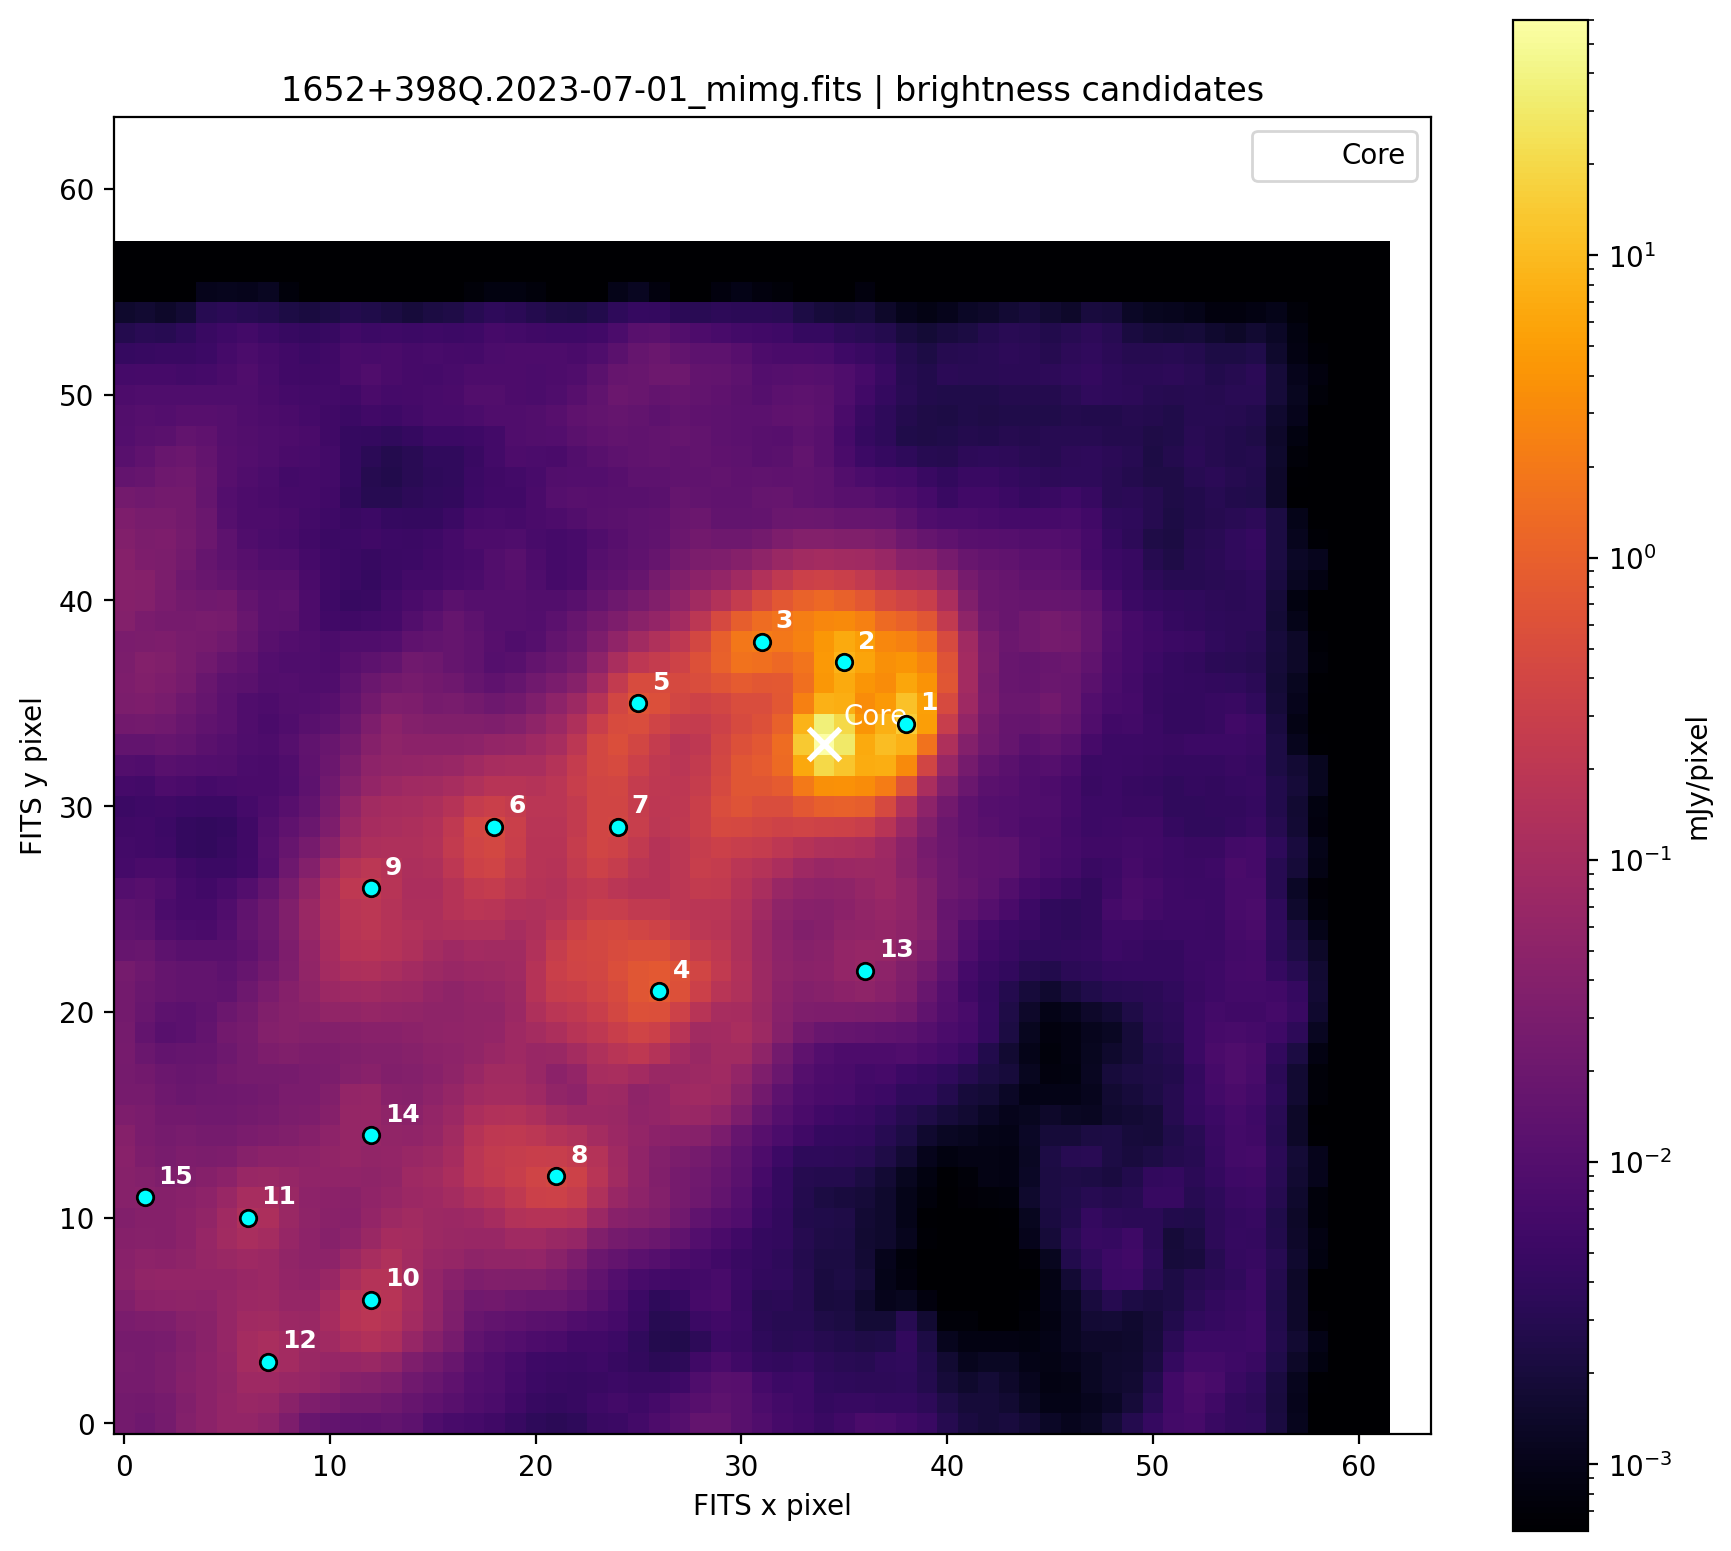

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking


In [269]:
# ============================================================
# 手順1：候補点の図とCSVを保存し、図をここに表示
# このセルまで上から順に実行する
# ============================================================
main(mode="candidates")


In [271]:
# ============================================================
# 手順2：上に表示された候補図を見て番号を指定
# コアに近い順など、結びたい順番で記入する
# 例: JET1_IDS = [4, 5, 12]、JET2_IDS = [1, 3, 2]
# ============================================================
JET1_IDS = [4,8,]
JET2_IDS = [1,2,3,5,6,9]


保存: /Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking/2023-07-01_jet_lines_no_numbers.png
保存: /Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking/02_selected_jet_points/2023-07-01.csv
保存: /Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking/03_jet_segment_angles/2023-07-01.csv


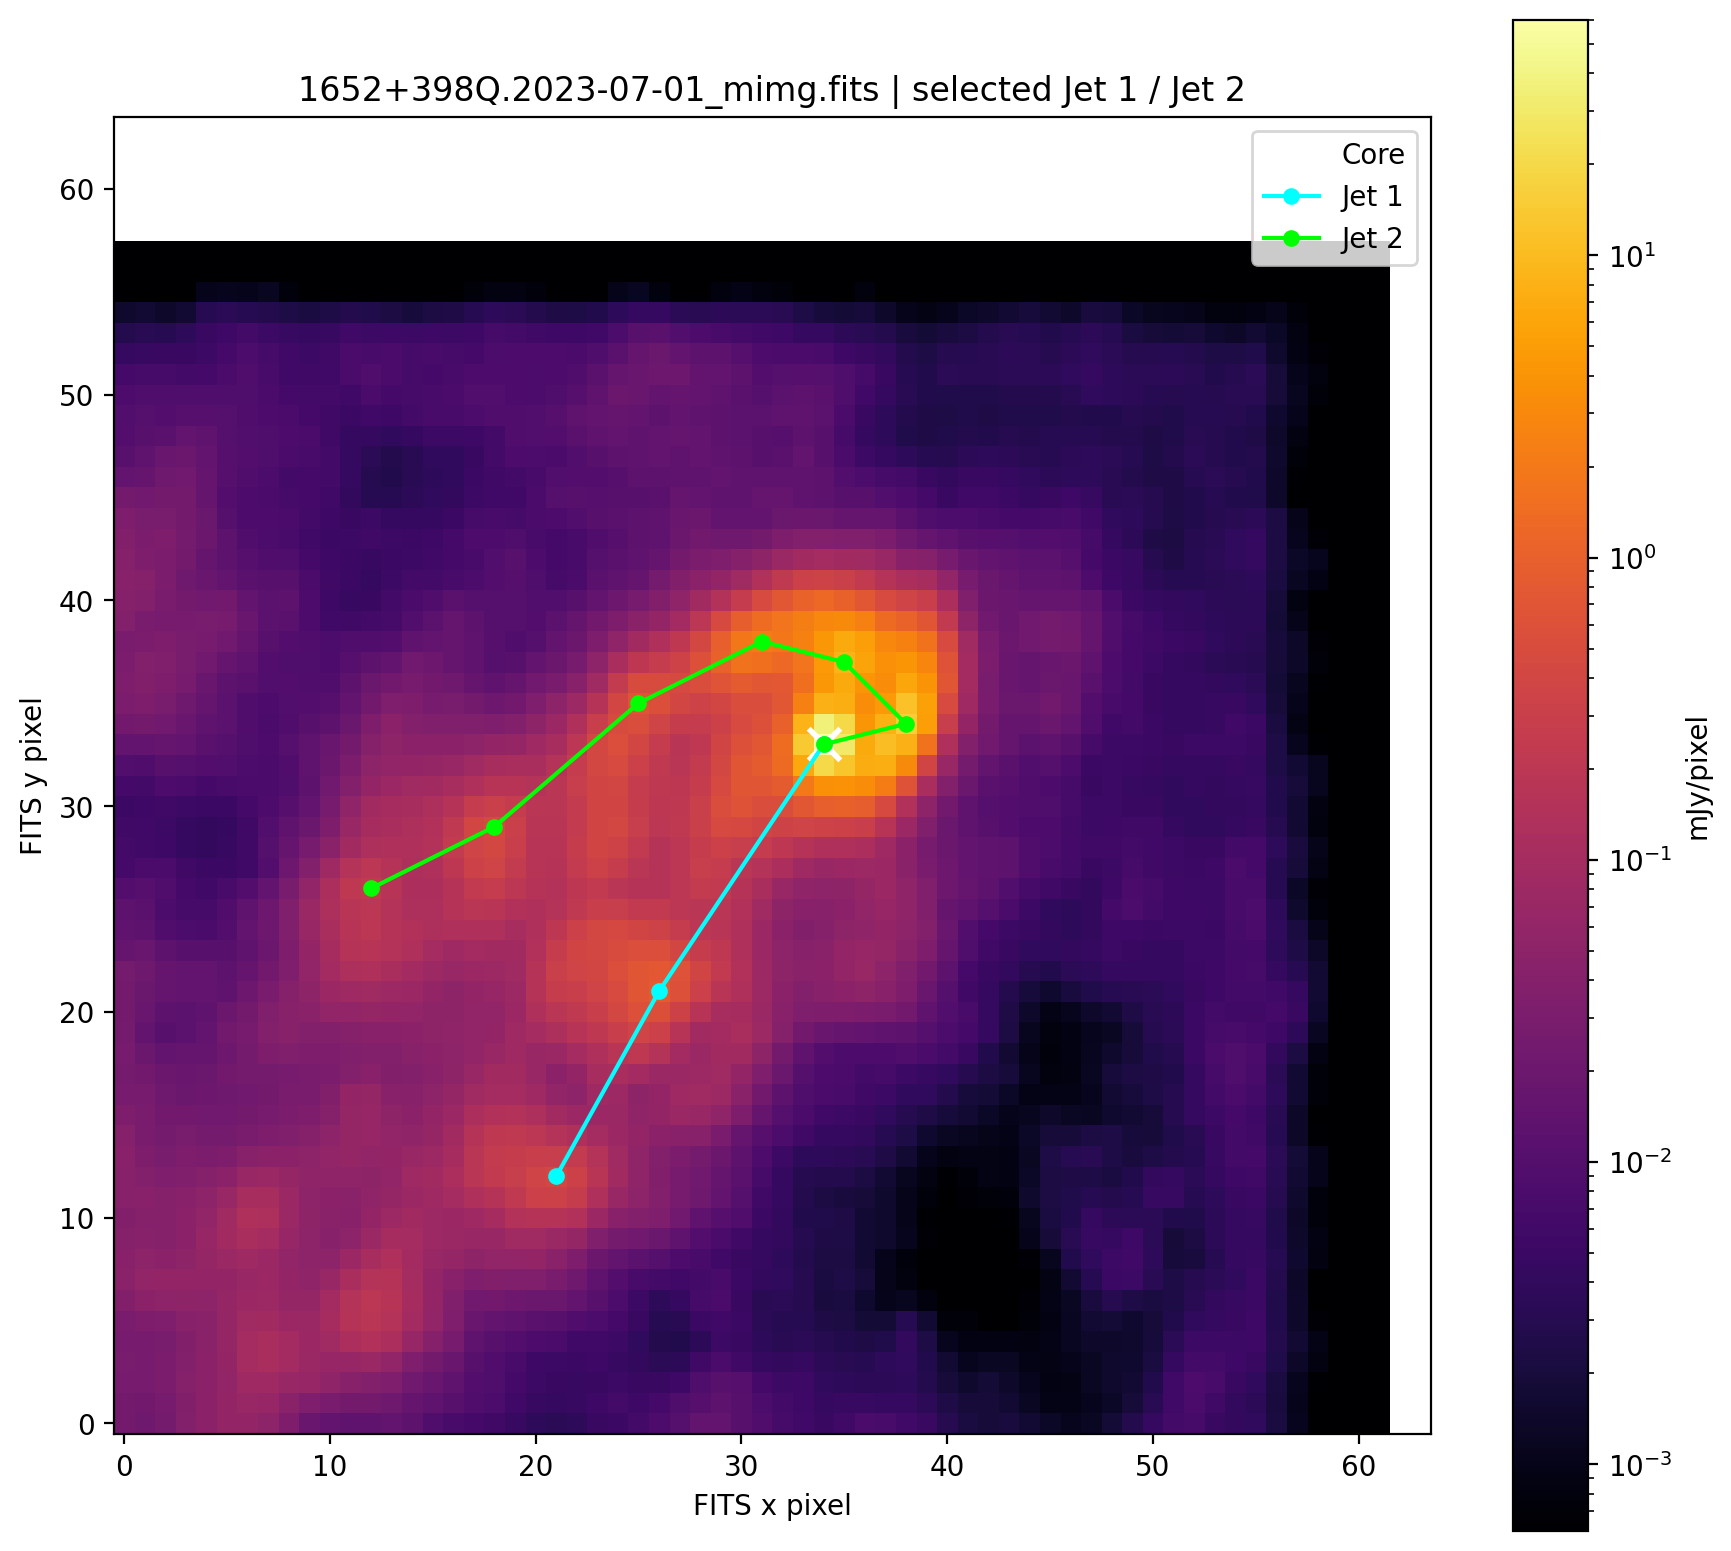

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov2500/Mrk501_2023-07-01/jet_tracking


In [273]:
# ============================================================
# 手順3：指定した候補を結んだ画像とCSVを保存・表示
# 番号を変えたら手順2とこのセルだけを再実行する
# ============================================================
if JET1_IDS or JET2_IDS:
    main(mode="selected")
else:
    print("手順2に候補番号を入力してから、このセルを実行してください")


In [2]:
CSVを開いて、縦軸輝度、横軸距離でグラフ作る
noise考慮してしきい値しっかりと

SyntaxError: invalid character '、' (U+3001) (225402153.py, line 1)